**Group information**

| Family name | First name | Email address |
| ----------- | ---------- | ------------- |
|             |            |               |
|             |            |               |
|             |            |               |

# Transformers - Solutions

This tutorial examines the use of deep language models to predict the topic distribution of political speech. We use a pre-trained BERT model (Bidirectional Encoder Representations from Transformers) from the [HuggingFace repository](https://huggingface.co/) to map sentences to a probability distribution over policy topics. The model is trained on datasets [Policy Agendas Project (PAP)](https://comparativeagendas.net/datasets_codebooks), an expert-coded corpus that classifies political texts into policy domains such as Macroeconomics, Defense, and Health. The trained model is then applied to presidential speeches from the [Miller Center Presidential Speech Archive](https://data.millercenter.org/) to infer the topic distribution of each sentence.

**Large language models** can be powerful learning tools, but make sure to continue asking questions until you fully understand the produced answer and can judge its correctness. Simply copy-pasting generated code does not contribute to learning and is a waste of your class time.

In [1]:
# On Google Colab
!pip install captum huggingface_hub sentence-transformers torchinfo

  Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl.metadata (61 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.9 MB/s  0:00:00
Using cached numpy-1.26.4-cp312-cp312-macosx_11_0_arm64.whl (13.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 80.3 MB/s  0:00:00
  Attempting uninstall: sympy
    Found existing installation: sympy 1.13.1
    Uninstalling sympy-1.13.1:
      Successfully uninstalled sympy-1.13.1━━━━━ 0/3 [sympy]
  Attempting uninstall: numpy━━━━━━━━━━━━━━━━━━━ 0/3 [sympy]
    Found existing installation: numpy 2.3.5 0/3 [sympy]
    Uninstalling numpy-2.3.5:━━━━━━━━━━━━━━━ 0/3 [sympy]
      Successfully uninstalled numpy-2.3.5━━ 0/3 [sympy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [captum]2m2/3 [captum]


In [2]:
# Packages
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import re
import shutil
import torch
import torchinfo
import transformers
import tqdm

from sklearn import metrics
from torch import nn, optim, utils
from urllib import request
tqdm.tqdm.pandas()

# Device
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
device = torch.device(device)

In [3]:
# Utilities
def download_data():
    if os.getcwd().endswith('/data'):
        print('Data folder already exists')
    else:
        request.urlretrieve('https://www.dropbox.com/scl/fo/j85w17txe37t5pom4akvm/ACl4S1N4f_noZsjhg0eLpFg?rlkey=gr2k43ycslvoj7zbfg64i9ulj&dl=1', 'data.zip')
        shutil.unpack_archive('data.zip', 'data')
        os.remove('data.zip')
        os.chdir('data')

In [4]:
# Execute on first run
# download_data()
os.chdir(os.path.expanduser('~/Library/CloudStorage/Dropbox/teaching/text_analysis/4_transformers/transformer_practice/political_data'))

**1. Descriptive statistics**

Load the `topic_dataset.csv` file and display a subset of texts with their associated topic labels. Compute topic frequences.

In [5]:
dataset = pd.read_csv('topic_dataset.csv')
dataset.topic.value_counts()

# Prints a sample of texts and labels
for _, row in dataset.sample(3).iterrows():
    print(f'TEXT:  {row.text}\nTOPIC: {row.topic}\n')

# Displays labels frequencies
print('FREQUENCIES:', dataset.topic.value_counts(), sep='\n')

TEXT:  He has closely identified the United States with the apartheid regime in South Africa, and he has time and again failed to confront dictators around the globe.
TOPIC: International Affairs

TEXT:  Our progress has been significant, and in many areas unprecedented.
TOPIC: Social Welfare

TEXT:  The Department of Justice, in particular, has been used improperly to achieve partisan political, economic, and legislative goals.
TOPIC: Government Operations

FREQUENCIES:
topic
International Affairs    5876
Defense                  3439
Macroeconomics           3219
Civil Rights             2793
Health                   2457
Law and Crime            2212
Government Operations    1998
Education                1975
Labor                    1364
Social Welfare           1350
Public Lands             1274
Housing                  1216
Energy                   1212
Environment              1148
Domestic Commerce        1026
Agriculture              1015
Foreign Trade             964
Technolo

**2. Compute embeddings**

Load the pre-trained BERT model (`bert-base-uncased`) using the Hugging Face `transformers` library, including both 

- The tokeniser `transformers.BertTokenizer.from_pretrained('bert-base-uncased')` 
- The model `transformers.BertModel.from_pretrained('bert-base-uncased'` 

Move the model to the appropriate device and set it to evaluation mode to disable training-specific layers such as dropout. Next, tokenise each text and pass it through the model to compute its embedding representation. For efficiency, you can process the texts in batches using PyTorch `utils.data.DataLoader`.

In [6]:
tokeniser  = transformers.BertTokenizer.from_pretrained('bert-base-uncased')
bert_model = transformers.BertModel.from_pretrained('bert-base-uncased')
bert_model.to(device)
bert_model.eval() 

loader = utils.data.DataLoader(dataset['text'], batch_size=32, shuffle=False)
embeds = []
for batch in tqdm.tqdm(loader):
    tokens = tokeniser(batch, padding=True, return_tensors='pt')
    with torch.no_grad():
        outputs = bert_model(**tokens.to(device))
    embeds.extend(outputs.pooler_output)

embeds = torch.stack(embeds).cpu()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
100%|██████████| 1141/1141 [01:06<00:00, 17.08it/s]


**4. Data loaders**

Format the response variable as a sequence of integers using `pd.factorize`, and convert the resulting codes to `torch.long`.

Create a tensor dataset using `utils.data.TensorDataset`, combining the input tensors and the response variable. Split the dataset into training (70%) and test sets, and optionally a validation sample, using `torch.utils.data.random_split`.

Finally, initialise the corresponding `utils.data.DataLoader` objects for each sample, ensuring that the training loader uses shuffling to randomise the order of observations during training.

In [7]:
topics = dataset['topic'].factorize()

tensor_dataset = utils.data.TensorDataset(embeds, torch.tensor(topics[0], dtype=torch.long))
train_dataset, val_dataset, test_dataset = utils.data.random_split(tensor_dataset, lengths=[0.70, 0.15, 0.15], generator=torch.Generator().manual_seed(0))

train_loader = utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = utils.data.DataLoader(val_dataset,   batch_size=32, shuffle=False)
test_loader  = utils.data.DataLoader(test_dataset,  batch_size=32, shuffle=False)

''' Checks a batch
x, y = next(iter(train_loader))
print(f'X: {x.shape}\nY: {y.shape}')
del x, y
'''

" Checks a batch\nx, y = next(iter(train_loader))\nprint(f'X: {x.shape}\nY: {y.shape}')\ndel x, y\n"

**5. Regression head**

Define a PyTorch model class that maps the BERT embeddings to a probability distribution over topics using a single linear layer, optionally preceded by a dropout layer for regularisation. In PyTorch, the output layer should return raw logits, as the activation function is applied internally by the loss function for numerical stability. Instantiate the model and inspect its architecture using `torchinfo.summary`.

Note: The encoder model (BERT) can be incorporated directly into the PyTorch model class, allowing the embeddings to be fine-tuned for the specific classification task. However, this approach requires large amounts of labelled training data and substantial computational resources.

In [8]:
class TopicClassifier(nn.Module):
    def __init__(self, input_dim, output_dim, dropout=0.0):
        super(TopicClassifier, self).__init__()
        self.dropout    = nn.Dropout(dropout)
        self.classifier = nn.Linear(input_dim, output_dim)
    
    def forward(self, X):
        H = self.dropout(X)
        Y = self.classifier(H)
        return Y
    
# Instantiates model
model = TopicClassifier(input_dim=bert_model.config.hidden_size, output_dim=len(topics[1]), dropout=0.1)
print(torchinfo.summary(model, input_data=torch.zeros((1, 768), dtype=torch.float)))

Layer (type:depth-idx)                   Output Shape              Param #
TopicClassifier                          [1, 20]                   --
├─Dropout: 1-1                           [1, 768]                  --
├─Linear: 1-2                            [1, 20]                   15,380
Total params: 15,380
Trainable params: 15,380
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.02
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.06
Estimated Total Size (MB): 0.06


**6. Model training** 

Define the appropriate loss function and an optimisation algorithm. Write a PyTorch training loop to estimate the model parameters using the training sample. Remember to move the model and the batch data to the correct device. Use a maximum of 50 epochs.

Optionally, implement an early-stopping procedure on the validation sample to monitor generalisation performance across epochs, stop training when overfitting begins, and restore the parameters that perform best out of sample.

In [9]:
# Define loss and optimiser
model     = model.to(device)
criterion = nn.CrossEntropyLoss(reduction='mean')
optimiser = optim.AdamW(model.parameters(), lr=1e-3)

In [10]:
class EarlyStopping:
    
    def __init__(self, patience=3, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = float('inf')
        self.count = 0
        self.best_state = None

    def step(self, val_loss, model):
        if val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.count = 0
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            return False
        else:
            self.count += 1
            return self.count >= self.patience
        
early_stopping = EarlyStopping(patience=5, min_delta=1e-4)

In [11]:
n_epochs = 50
for epoch in range(n_epochs):

    # Training
    model.train()
    train_obs, train_loss = 0, 0
    progress = tqdm.tqdm(train_loader, desc=f'Epoch {epoch+1:02d}/{n_epochs}', unit='batch')
    for x, y in progress:
        x, y = x.to(device), y.to(device)
        optimiser.zero_grad()
        logits = model(x)
        loss   = criterion(logits.squeeze(), y)
        loss.backward()
        optimiser.step()
        train_obs  += x.size(0)
        train_loss += loss.item() * x.size(0)
        progress.set_postfix(train_loss=f'{train_loss / train_obs:.4f}')

    # Validation
    model.eval()
    val_obs, val_loss = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss   = criterion(logits.squeeze(), y)
            val_obs  += x.size(0)
            val_loss += loss.item() * x.size(0)
    
    # Early stopping
    if early_stopping.step(val_loss / val_obs, model):
        print(f'Early stopping at epoch {epoch+1}')
        break

# Restores best model and saves
model.load_state_dict(early_stopping.best_state)
torch.save(model.state_dict(), 'topic_model.pth')

Epoch 33/50: 100%|██████████| 799/799 [00:01<00:00, 418.13batch/s, train_loss=1.9186]


Early stopping at epoch 33


**7. Model performance** 

Write a PyTorch prediction loop to evaluate the model's generalisation performance on the test sample. Set the model to evaluation mode and disable gradient computation using `torch.no_grad()`. Collect the predicted labels and true labels across batches.

Use Scikit-learn's `metrics.classification_report` and `metrics.confusion_matrix` to summarise classification performance.

                       precision    recall  f1-score   support

       Macroeconomics       0.42      0.68      0.52       478
         Civil Rights       0.30      0.58      0.40       419
               Health       0.67      0.62      0.64       354
          Agriculture       0.69      0.36      0.47       161
                Labor       0.56      0.41      0.47       190
            Education       0.55      0.62      0.58       299
          Environment       0.55      0.38      0.45       197
               Energy       0.47      0.63      0.54       185
          Immigration       0.83      0.16      0.27        93
       Transportation       0.80      0.24      0.37       115
       Social Welfare       0.56      0.12      0.19       187
              Housing       0.55      0.41      0.47       175
    Domestic Commerce       0.47      0.16      0.24       158
              Defense       0.57      0.50      0.53       527
           Technology       0.50      0.01      0.02  

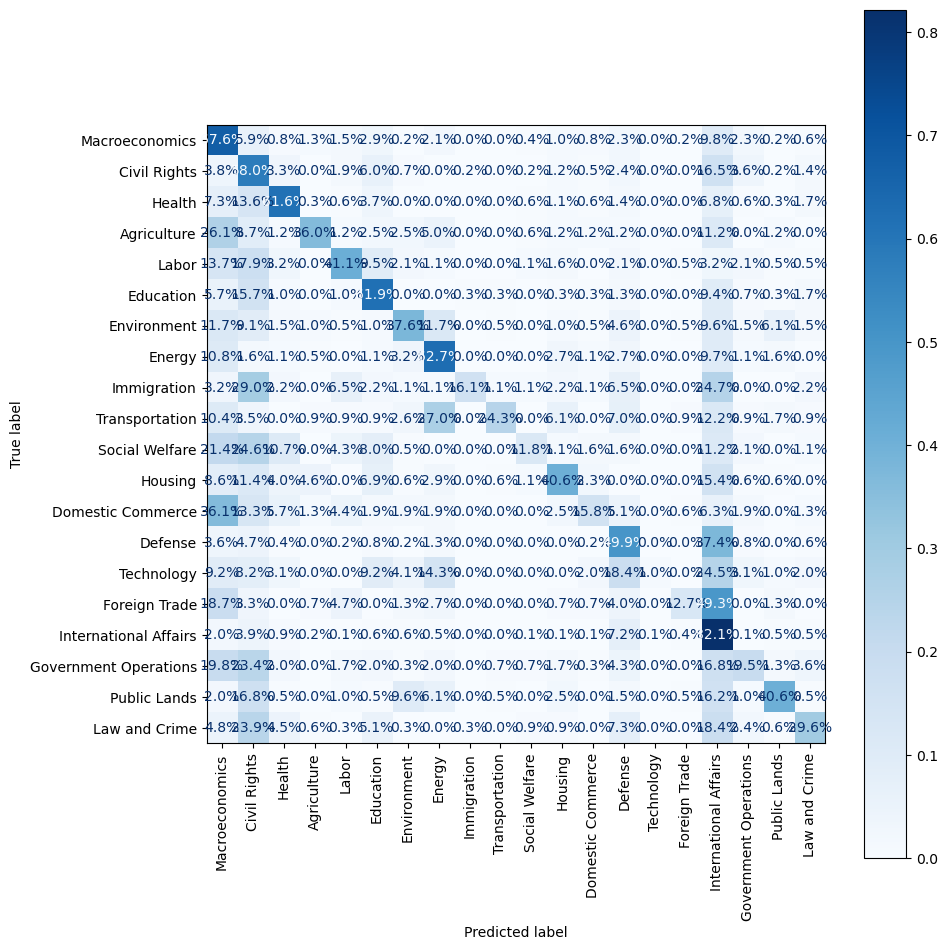

In [12]:
# Loads the parameters of the pre-trained model
model.load_state_dict(torch.load('topic_model.pth', weights_only=False))
model.to(device)
model.eval()

# Evaluation loop
P_test = []
with torch.no_grad():
    for x, y in test_loader:
        logits = model(x.to(device))
        probas = torch.softmax(logits, dim=1)
        P_test.append(probas.squeeze())

P_test  = torch.cat(P_test).detach().cpu()
Yh_test = P_test.argmax(dim=1)
Y_test  = tensor_dataset.tensors[1][test_dataset.indices]

# Classification metrics
print(metrics.classification_report(Y_test, Yh_test, target_names=topics[1], zero_division=0))

# Confusion matrix (row-normalised)
fig, ax = plt.subplots(figsize=(10, 10))
metrics.ConfusionMatrixDisplay.from_predictions(Y_test, Yh_test, display_labels=topics[1], normalize='true', values_format='.1%', cmap='Blues', xticks_rotation='vertical', ax=ax)
plt.tight_layout()
plt.show()

**8. Prediction**

Load the `speech_dataset.csv` file and implement a simple tokeniser that splits text on punctuation and removes sentences containing fewer than five words.

Write a PyTorch prediction loop that processes each sentence by applying the tokeniser, computing BERT embeddings, and using the trained classification model to predict the topic of each sentence. Predict the topic distribution of speeches for selected presidents.

In [13]:
# Loads speech dataset
speeches = pd.read_csv('speech_dataset.csv')

# Splits sentence
def split_sentences(text:str, min_length:int=5) -> list:
    sentences = re.split(r'(?<=[.!?])\s+(?=[A-Z])', text)
    sentences = [s.strip() for s in sentences if s.strip() and len(s.split()) > min_length]
    return sentences

# Predicts topics for each speech
P_pred = []
subset = speeches[speeches['president'].isin(['Barack Obama', 'George Washington'])]
for speech in tqdm.tqdm(subset['transcript'], desc='Predicting topics', unit='speech'):
    inputs = split_sentences(speech)
    inputs = tokeniser(inputs, padding=True, truncation=True, return_tensors='pt')
    with torch.no_grad():
        embeds = bert_model(**inputs.to(device)).pooler_output
        logits = model(embeds)
    probas = torch.softmax(logits, dim=1)
    probas = torch.mean(probas, dim=0)
    P_pred.append(probas)

P_pred = torch.stack(P_pred).cpu()


Predicting topics: 100%|██████████| 72/72 [00:25<00:00,  2.82speech/s]


**9. Comparisons**

Using the previous results, perform further analysis and comparisons, such as plotting the average topic distribution by president or examining how the prevalence of specific topics evolves over time.

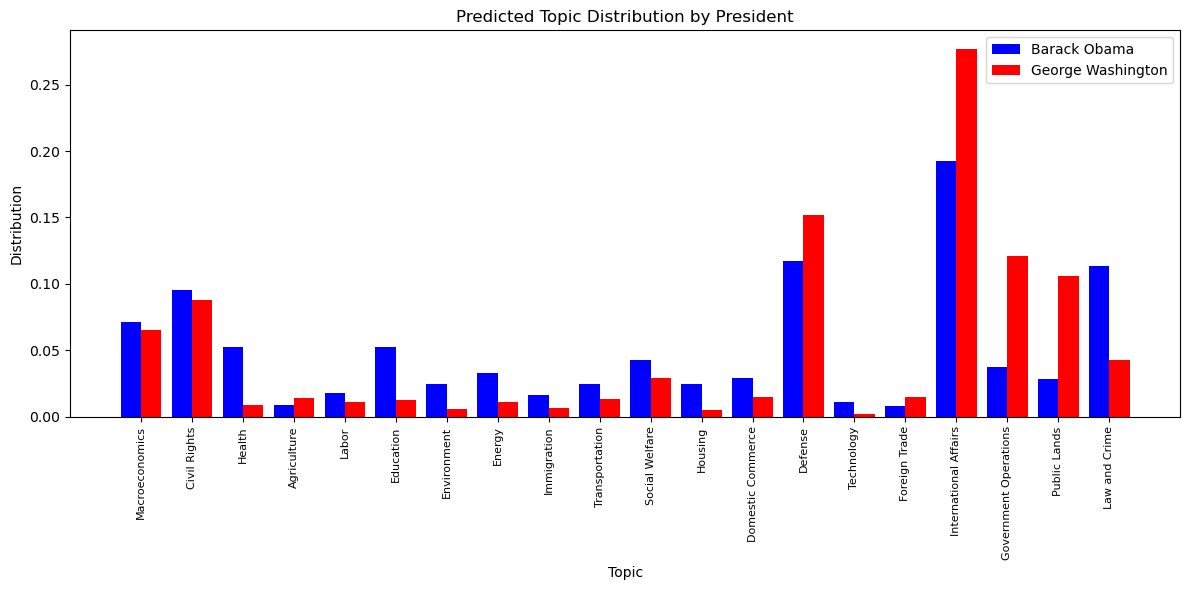

In [14]:

# Formats predictions for plotting
figdata = pd.DataFrame(P_pred, columns=topics[1])
figdata = pd.concat([subset[['president']].reset_index(drop=True), pd.DataFrame(figdata)], axis=1)
figdata = figdata.groupby('president').mean()

# Figure
width = 0.4
x     = np.arange(len(topics[1]))
plt.figure(figsize=(12, 6))
plt.bar(x - width/2, figdata.loc['Barack Obama'], width=width, color='blue', label='Barack Obama')
plt.bar(x + width/2, figdata.loc['George Washington'], width=width, color='red',  label='George Washington')
plt.xticks(np.arange(len(topics[1])), topics[1], rotation=90, fontsize=8)
plt.xlabel('Topic')
plt.ylabel('Distribution')
plt.title('Predicted Topic Distribution by President')
plt.legend()
plt.tight_layout()
plt.show()
plt.close()